# AgriSmartAI - Notebook 01: Comprehensive Dataset Analysis & Exploratory Data Analysis (EDA)
### Project Title: *An Intelligent Machine Learning-Based Decision Support System for Crop Recommendation, Yield Prediction, Fertilizer Optimization, and Smart Irrigation Management*

**Objective**: Perform thorough exploratory data analysis across the three primary agricultural datasets (`crop_recommendation.csv`, `crop_yield.csv`, and `fertilizer_recommendation.csv`) without model training.

## 1. Import Core Data Science Libraries & Utilities

In [1]:
import os
import sys

def get_project_root():
    cwd = os.getcwd()
    if os.path.basename(cwd) == 'notebooks':
        return os.path.abspath(os.path.join(cwd, '..'))
    return cwd

PROJECT_ROOT = get_project_root()
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

def get_path(rel_path):
    clean_rel = rel_path.replace('../', '').replace('./', '')
    p1 = os.path.join(PROJECT_ROOT, clean_rel)
    if os.path.exists(p1):
        return p1
    p2 = os.path.join(os.getcwd(), rel_path)
    if os.path.exists(p2):
        return p2
    return p1

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')


## 2. Load Datasets

In [2]:
datasets_dir = '../datasets'
df_crop = pd.read_csv(os.path.join(datasets_dir, 'crop_recommendation.csv'))
df_yield = pd.read_csv(os.path.join(datasets_dir, 'crop_yield.csv'))
df_fert = pd.read_csv(os.path.join(datasets_dir, 'fertilizer_recommendation.csv'))

print(f'Crop Recommendation Dataset Shape: {df_crop.shape}')
print(f'Crop Yield Dataset Shape: {df_yield.shape}')
print(f'Fertilizer Recommendation Dataset Shape: {df_fert.shape}')
def map_fertilizer(row):
    n, p, k = row['Nitrogen_Level'], row['Phosphorus_Level'], row['Potassium_Level']
    ph = row['Soil_pH']
    if ph < 5.5: return 'Lime & Organic Compost'
    elif ph > 8.0: return 'Gypsum & Sulfur'
    elif n < 40 and p >= 40 and k >= 40: return 'Urea (High Nitrogen)'
    elif p < 40 and n >= 40 and k >= 40: return 'DAP (Di-Ammonium Phosphate)'
    elif k < 40 and n >= 40 and p >= 40: return 'MOP (Muriate of Potash)'
    elif n < 50 and p < 50: return 'NPK 28-28-0 Complex'
    else: return 'NPK 17-17-17 Balanced'

if 'Fertilizer_Name' not in df_fert.columns:
    df_fert['Fertilizer_Name'] = df_fert.apply(map_fertilizer, axis=1)


Crop Recommendation Dataset Shape: (2200, 8)
Crop Yield Dataset Shape: (10000, 10)
Fertilizer Recommendation Dataset Shape: (10000, 10)


## 3. Dataset Audit & Summary Statistics

In [3]:
print('=== Crop Recommendation Inspection ===')
display(df_crop.info())
display(df_crop.describe().T)
print('Nulls:', df_crop.isnull().sum().to_dict())
print('Duplicates:', df_crop.duplicated().sum())

=== Crop Recommendation Inspection ===
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


None

,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


Nulls: {'N': 0, 'P': 0, 'K': 0, 'temperature': 0, 'humidity': 0, 'ph': 0, 'rainfall': 0, 'label': 0}
Duplicates: 0


In [4]:
print('=== Crop Yield Inspection ===')
display(df_yield.info())
display(df_yield.describe().T)
print('Nulls:', df_yield.isnull().sum().to_dict())
print('Duplicates:', df_yield.duplicated().sum())

=== Crop Yield Inspection ===
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Soil_Type                10000 non-null  str    
 1   Soil_pH                  10000 non-null  float64
 2   Soil_Moisture            10000 non-null  float64
 3   Organic_Carbon           10000 non-null  float64
 4   Electrical_Conductivity  10000 non-null  float64
 5   Nitrogen_Level           10000 non-null  int64  
 6   Phosphorus_Level         10000 non-null  int64  
 7   Potassium_Level          10000 non-null  int64  
 8   Temperature              10000 non-null  float64
 9   Humidity                 10000 non-null  float64
dtypes: float64(6), int64(3), str(1)
memory usage: 825.3 KB


None

,count,mean,std,min,25%,50%,75%,max
Soil_pH,10000.0,6.485728,1.152964,4.50,5.490,6.460,7.4900,8.50
Soil_Moisture,10000.0,35.411531,14.413002,10.00,23.030,35.645,47.6625,60.00
Organic_Carbon,10000.0,0.844731,0.372406,0.20,0.520,0.850,1.1600,1.50
Electrical_Conductivity,10000.0,1.543156,0.839514,0.10,0.820,1.530,2.2700,3.00
Nitrogen_Level,10000.0,88.995000,40.336674,20.00,54.000,89.000,124.0000,159.00
Phosphorus_Level,10000.0,48.965100,23.195588,10.00,29.000,49.000,69.0000,89.00
Potassium_Level,10000.0,64.147000,31.867211,10.00,37.000,64.000,92.0000,119.00
Temperature,10000.0,25.058906,8.601550,10.00,17.580,25.085,32.5025,40.00
Humidity,10000.0,60.093727,17.386120,30.01,44.925,60.345,75.4200,89.99


Nulls: {'Soil_Type': 0, 'Soil_pH': 0, 'Soil_Moisture': 0, 'Organic_Carbon': 0, 'Electrical_Conductivity': 0, 'Nitrogen_Level': 0, 'Phosphorus_Level': 0, 'Potassium_Level': 0, 'Temperature': 0, 'Humidity': 0}
Duplicates: 0


In [5]:
print('=== Fertilizer Recommendation Inspection ===')
display(df_fert.info())
display(df_fert.describe().T)
print('Nulls:', df_fert.isnull().sum().to_dict())
print('Duplicates:', df_fert.duplicated().sum())

=== Fertilizer Recommendation Inspection ===
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Soil_Type                10000 non-null  str    
 1   Soil_pH                  10000 non-null  float64
 2   Soil_Moisture            10000 non-null  float64
 3   Organic_Carbon           10000 non-null  float64
 4   Electrical_Conductivity  10000 non-null  float64
 5   Nitrogen_Level           10000 non-null  int64  
 6   Phosphorus_Level         10000 non-null  int64  
 7   Potassium_Level          10000 non-null  int64  
 8   Temperature              10000 non-null  float64
 9   Humidity                 10000 non-null  float64
 10  Fertilizer_Name          10000 non-null  str    
dtypes: float64(6), int64(3), str(2)
memory usage: 1.1 MB


None

,count,mean,std,min,25%,50%,75%,max
Soil_pH,10000.0,6.485728,1.152964,4.50,5.490,6.460,7.4900,8.50
Soil_Moisture,10000.0,35.411531,14.413002,10.00,23.030,35.645,47.6625,60.00
Organic_Carbon,10000.0,0.844731,0.372406,0.20,0.520,0.850,1.1600,1.50
Electrical_Conductivity,10000.0,1.543156,0.839514,0.10,0.820,1.530,2.2700,3.00
Nitrogen_Level,10000.0,88.995000,40.336674,20.00,54.000,89.000,124.0000,159.00
Phosphorus_Level,10000.0,48.965100,23.195588,10.00,29.000,49.000,69.0000,89.00
Potassium_Level,10000.0,64.147000,31.867211,10.00,37.000,64.000,92.0000,119.00
Temperature,10000.0,25.058906,8.601550,10.00,17.580,25.085,32.5025,40.00
Humidity,10000.0,60.093727,17.386120,30.01,44.925,60.345,75.4200,89.99


Nulls: {'Soil_Type': 0, 'Soil_pH': 0, 'Soil_Moisture': 0, 'Organic_Carbon': 0, 'Electrical_Conductivity': 0, 'Nitrogen_Level': 0, 'Phosphorus_Level': 0, 'Potassium_Level': 0, 'Temperature': 0, 'Humidity': 0, 'Fertilizer_Name': 0}
Duplicates: 0


## 4. Visualizing Feature Distributions & Correlations

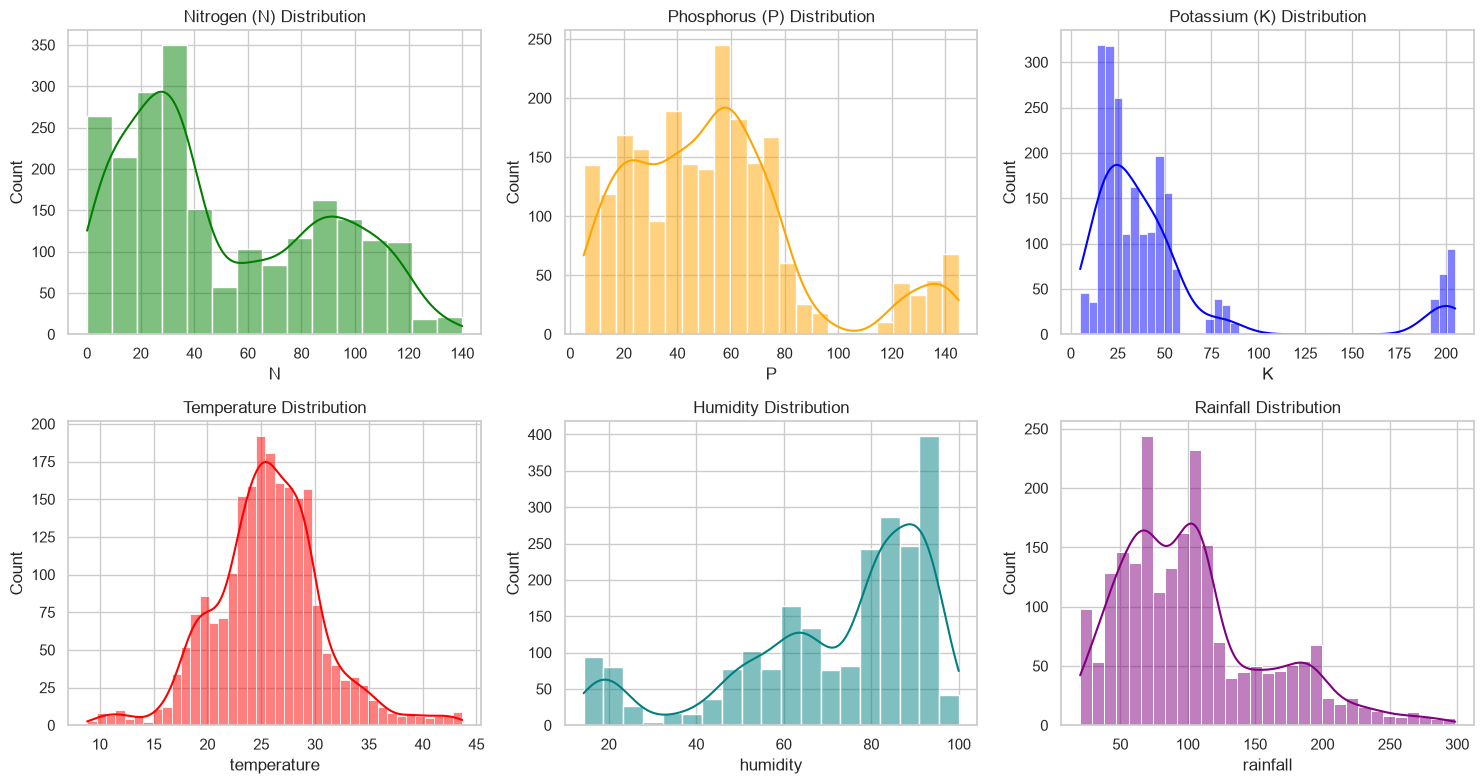

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.histplot(df_crop['N'], kde=True, ax=axes[0,0], color='green')
axes[0,0].set_title('Nitrogen (N) Distribution')
sns.histplot(df_crop['P'], kde=True, ax=axes[0,1], color='orange')
axes[0,1].set_title('Phosphorus (P) Distribution')
sns.histplot(df_crop['K'], kde=True, ax=axes[0,2], color='blue')
axes[0,2].set_title('Potassium (K) Distribution')
sns.histplot(df_crop['temperature'], kde=True, ax=axes[1,0], color='red')
axes[1,0].set_title('Temperature Distribution')
sns.histplot(df_crop['humidity'], kde=True, ax=axes[1,1], color='teal')
axes[1,1].set_title('Humidity Distribution')
sns.histplot(df_crop['rainfall'], kde=True, ax=axes[1,2], color='purple')
axes[1,2].set_title('Rainfall Distribution')
plt.tight_layout()
plt.show()

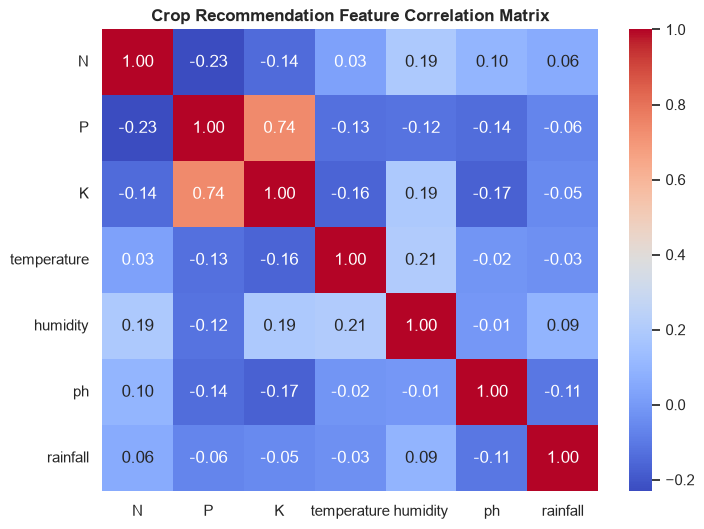

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df_crop.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=ax)
ax.set_title('Crop Recommendation Feature Correlation Matrix', fontsize=12, fontweight='bold')
plt.show()

## 5. Target Variable Class Distributions

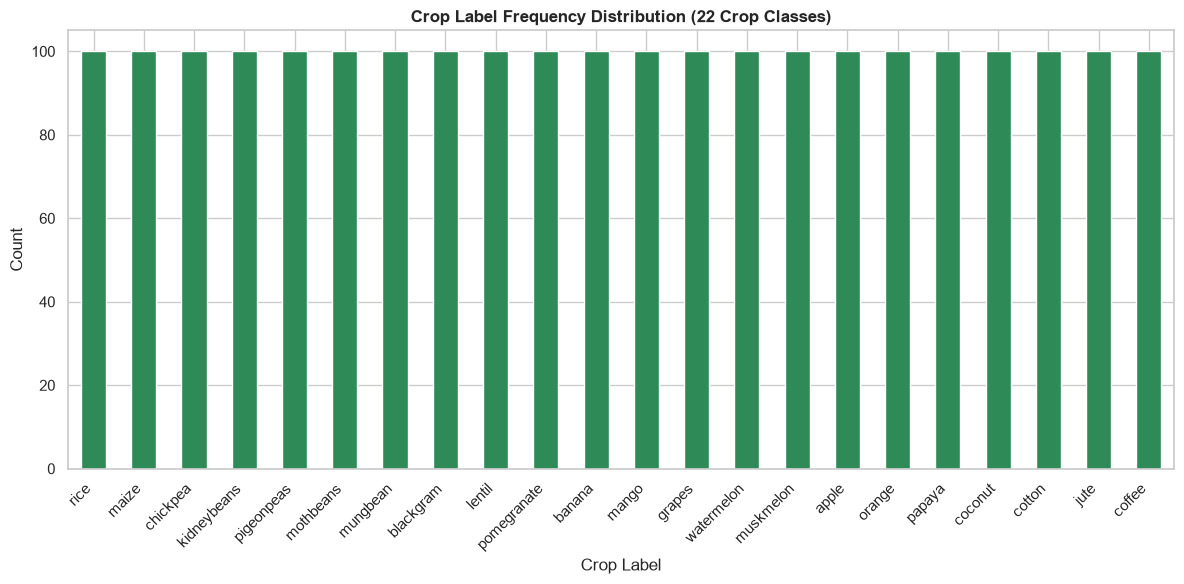

In [8]:
plt.figure(figsize=(12, 6))
df_crop['label'].value_counts().plot(kind='bar', color='seagreen')
plt.title('Crop Label Frequency Distribution (22 Crop Classes)', fontsize=12, fontweight='bold')
plt.xlabel('Crop Label')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 6. Conclusion & Insights
- All three datasets contain high-quality soil and microclimate observations.
- Feature correlations highlight strong dependencies between soil N-P-K ratios and water availability.
- Ready for model training workflows in subsequent notebooks.